# Quantum-Assisted Multi-Agent System Optimization for Autonomous Swarms

### Classical A* Algorithm, a Quantum-Inspired (QUBO) Extension

**Dataset:** Moving AI Lab MAPF benchmark – map `random-32-32-10` with its *even* and *random* scenario files.

To keep the problem manageable, I use a **20 × 20 window** (top-left corner) of the map and consider only the scenario entries whose start and goal positions lie inside this window.

---

## Flow of Implementation

1. **Problem Understanding:** Define the environment, drone agents, movement rules and collision challenges.

2. **Dataset Preparation:** Load the map and scenario files, select the 20 × 20 region and analyse the available start and goal positions.

3. **Environment Development:** Create the grid environment and represent individual drones using object-oriented programming.

4. **Pathfinding:** Implement the A* algorithm to find paths from each drone's starting position to its target.

5. **Multi-Agent Coordination:** Apply Prioritized Planning and reservation mechanisms to avoid conflicts between drones.

6. **Simulation and Experiments:** Run simulations for 2-drone and 5-drone scenarios and compare the results.

7. **Testing and Validation:** Test pathfinding, obstacle avoidance, collision detection and coordination.

8. **QUBO Optimization:** Formulate route selection as a QUBO problem and evaluate it using Simulated Annealing.

9. **Result Analysis:** Compare the approaches, discuss observations and identify possible improvements.

---

**Libraries Required:** `numpy`, `pandas` and `matplotlib`.

# 1. Understanding the Problem

Multi-Agent Path Finding (MAPF) is a path-planning problem in which multiple agents must travel from their starting positions to their respective destinations in the same environment. In this project, the agents are autonomous drones. The main challenge is to find safe and efficient paths for all drones while avoiding obstacles and preventing collisions.

## 1.1 Environment and Representation

The environment is represented as a 2D grid, consisting of rows and columns. Each cell in the grid represents a possible position for a drone.

There are two types of cells:

**Free cells**: Positions where drones can move.

**Obstacle cells**: Blocked positions that drones must avoid.

The grid can also be viewed as a graph, where each free cell represents a vertex (node), and connections between neighbouring free cells represent possible movements.

Each cell is identified by coordinates (x, y), where x represents the column and y represents the row. The coordinate (0, 0) is at the top-left corner, following the Moving AI dataset convention.

1.2 Drones, Start Positions, and Goals

In this project, each drone is treated as an individual agent. Every agent has a starting position and a destination that it must reach.

The important details of each agent are:

**Start Position**: The cell where the drone begins its journey.

**Goal Position**: The cell that the drone needs to reach.

**Path**: A sequence of connected cells from the start position to the goal position.

The start and goal positions are obtained from the Moving AI scenario (.scen) files. All drones must reach their assigned goals without entering obstacle cells or creating conflicts with other drones.

# 2. Dataset Loading and Exploratory Data Analysis (EDA)

In [96]:
import os, glob, math, time, heapq, zipfile, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SQRT2 = math.sqrt(2)
COLORS = plt.cm.tab10.colors            # every drone keeps the same colour in all plots

In [97]:
#finding the dataset files 
MAP_NAME = "random-32-32-10"                                # name of the benchmark map used in this project

def find_files(ext):
    # Search for all files with the given extension (.map, .scen, .zip) inside these folders
    hits = []
    for folder in ["Data", "../Data", "data", "../data", "."]:
        hits += glob.glob(os.path.join(folder, "**", "*" + ext), recursive=True)   # ** = also searching inside sub-folders
    return {os.path.basename(h): os.path.abspath(h) for h in sorted(hits)}      # dictionary: file name = full path

def have_data():
    # True only if the correct map file AND its "even" scenario files are present
    maps, scens = find_files(".map"), find_files(".scen")
    return (MAP_NAME + ".map") in maps and any(n.startswith(MAP_NAME + "-even-") for n in scens)

if not have_data():              #data is missing =try to extract all ZIP files
    os.makedirs("mapf_data", exist_ok=True)                 #new folder where the ZIP contents will be extracted
    for z in find_files(".zip").values():
        zipfile.ZipFile(z).extractall("mapf_data")

map_files, scen_files = find_files(".map"), find_files(".scen")      #all map and scenario files found


def natural(name):                                          #sorts '...-2.scen' before '...-10.scen' (number order, not text order)
    return int(name.rsplit("-", 1)[1].split(".")[0])        #takes the number at the end of the file name

#functions to read the files 
def load_map(path):
    rows = [r.strip() for r in open(path).read().splitlines()]       #read the file line by line
    rows = [r for r in rows[rows.index("map") + 1:] if r]            #keep only the grid rows (they come after the word "map")
    return np.array([[0 if ch in ".GS" else 1 for ch in r] for r in rows])   #0 = free, 1 = obstacle
def load_scen(path):
                                               # A .scen file has one line per drone: start (sx, sy), goal (gx, gy) and the optimal path length
    cols = ["bucket", "map", "width", "height", "sx", "sy", "gx", "gy", "optimal"]
    return pd.read_csv(path, sep="\t", skiprows=1, header=None, names=cols)     # tab separated, first line (version) skipped
                                                            #make the 20 x 20 grid from the 32 x 32 map 
full_map = load_map(map_files[MAP_NAME + ".map"])         #the complete 32 x 32 benchmark map
N = 20                                               #I use the top-left N x N window of the benchmark map
grid_array = full_map[:N, :N]                              #cut the window first 20 rows and first 20 columns
def inside_window(df):
    # Keep only the scenario entries whose start and goal are inside the window, on free cells, and different.
    keep = [max(r.sx, r.sy, r.gx, r.gy) < N and grid_array[r.sy, r.sx] == 0 and grid_array[r.gy, r.gx] == 0
            and (r.sx, r.sy) != (r.gx, r.gy) for r in df.itertuples()]      # True = keep this row, False = remove it
    return df[keep].reset_index(drop=True)                 # filter the rows and renumber them from 0

# load all "even" scenario files and filter them 
even_scens = {n: inside_window(load_scen(p)) for n, p in sorted(scen_files.items(), key=lambda kv: natural(kv[0])) if n.startswith(MAP_NAME + "-even-")}   # dictionary: file name -> table of valid drones
print("Using map file:", map_files[MAP_NAME + ".map"])     # showing which map file i was used
print(f"Benchmark map {full_map.shape[1]} x {full_map.shape[0]} -> window {N} x {N} | even scenario files: {len(even_scens)} "
      f"(entries inside the window per file: {min(map(len, even_scens.values()))} to {max(map(len, even_scens.values()))})")   # summary of what was loaded

Using map file: C:\Users\DELL\Documents\quantum-assisted-multi-agent-optimization\data\random-32-32-10.map
Benchmark map 32 x 32 -> window 20 x 20 | even scenario files: 25 (entries inside the window per file: 6 to 17)


,value
Grid size (columns x rows),20 x 20
Total cells,400
Free cells,351
Obstacle cells,49
Obstacle density (%),12.3
Scenario entries inside the window (25 files),324
Start-goal distance - mean,8.1
Start-goal distance - min / max,1.0 / 23.1


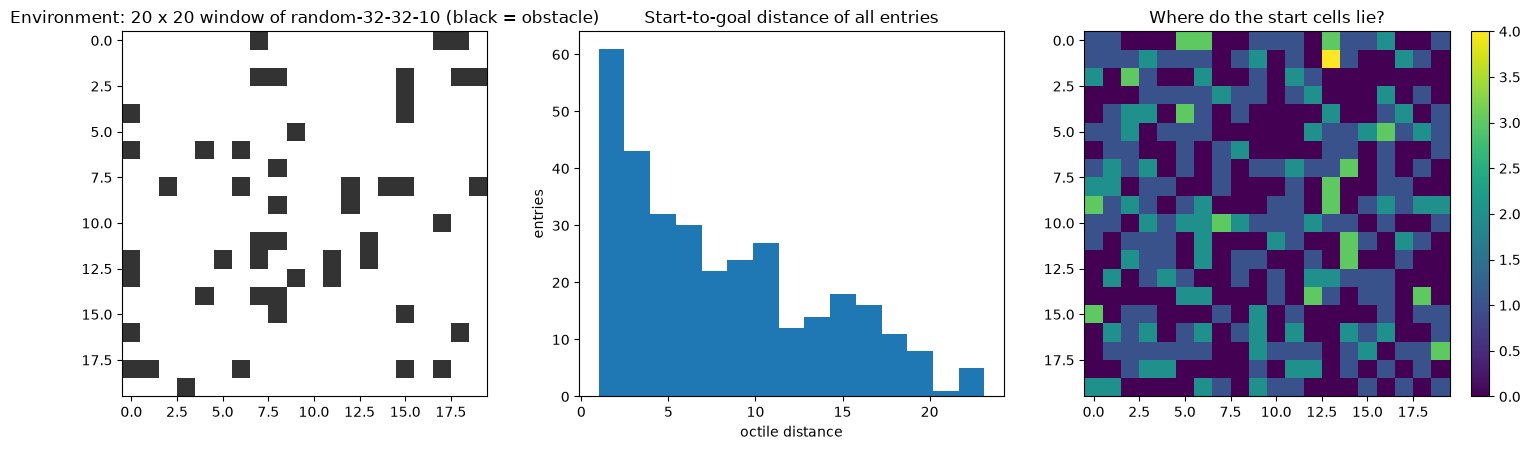

In [98]:
#Part a)summary statistics of the environment and of the scenario entries
all_even = pd.concat(even_scens.values())                       #join the tables of all 25 scenario files into one big table
dx, dy = (all_even.gx - all_even.sx).abs(), (all_even.gy - all_even.sy).abs()      # horizontal and vertical distance between start and goal
all_even["straight"] = np.maximum(dx, dy) + (SQRT2 - 1) * np.minimum(dx, dy)     # straight-line (octile) distance start -> goal, new column
free = int((grid_array == 0).sum())                        #number of free cells (value 0)
env_stats = pd.Series({                                #small table with the main numbers of the environment
    "Grid size (columns x rows)": f"{N} x {N}", "Total cells": grid_array.size, "Free cells": free,
    "Obstacle cells": grid_array.size - free, "Obstacle density (%)": round(100 * (1 - free / grid_array.size), 1),   # obstacle % = 100 x (1 - free/total)
    "Scenario entries inside the window (25 files)": len(all_even),            # how many drone pairs fit in the 20 x 20 window
    "Start-goal distance - mean": round(all_even.straight.mean(), 1),      # average trip length
    "Start-goal distance - min / max": f"{all_even.straight.min():.1f} / {all_even.straight.max():.1f}"}, name="value")   # shortest and longest trip
display(env_stats.to_frame())                              #displaying the table 

# Part b): 3 plots
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))            # one row with 3 plots side by side
ax[0].imshow(grid_array, cmap=ListedColormap(["white", "#333333"]))          # plot1: the map (white = free, dark = obstacle)
ax[0].set_title(f"Environment: {N} x {N} window of {MAP_NAME} (black = obstacle)")
ax[1].hist(all_even.straight, bins=15, color="tab:blue")                     # plot2: histogram of trip lengths
ax[1].set(title="Start-to-goal distance of all entries", xlabel="octile distance", ylabel="entries")
dens = np.histogram2d(all_even.sy, all_even.sx, bins=[range(N + 1), range(N + 1)])[0]     # count how many start cells fall in each grid cell
im = ax[2].imshow(dens, cmap="viridis"); ax[2].set_title("Where do the start cells lie?"); plt.colorbar(im, ax=ax[2], fraction=0.046)   # plot3: heat map of start positions
plt.tight_layout(); plt.show()                             # arrange the plots neatly and display them

**Observations.** The 20 × 20 window has about 12 % obstacles (scattered single cells), so there are many narrow diagonal gaps. Start and goal cells are spread over the whole window and the trips are medium-to-long compared with its width, so the shortest routes of different drones are likely to cross.

# 3. Object-Oriented Solution

The code is split into 5 classes. Each class has one job.

| Class | purpose |
|---|---|
| `Grid` | The map. It knows which cells are free or blocked, which moves are allowed (8 directions), and what each move costs. |
| `Drone` | One drone. It stores its start, goal and planned path. |
| `Planner` | Finds a path with **A\***. If it gets the "reserved cells" list, it also plans over time and can **wait**. |
| `Reservations` | A notebook of which cells are already taken at which time step. |
| `Coordinator` | Plans all drones, either one by one without caring about the others, or with **prioritized planning**. |

**A\* in simple words:** at every step, A\* looks at the cell that seems cheapest to reach the goal. Its score is *cost so far + estimated cost left*. The estimate never guesses too high, so A\* always finds the shortest path.

**Prioritized planning in simple words:**
1. Drones with the longest trip go first.
2. The first drone plans its path and **reserves** the cells it will use at each time step.
3. The next drone plans around those reservations. If a cell is taken, it takes a detour or **waits**.
4. A drone that has arrived stays at its goal, so that cell stays reserved.

In [99]:
class Grid:
    #The environment. Cell = (x, y); array value 0 = free, 1 = obstacle.
    MOVES = [(1, 0), (-1, 0), (0, 1), (0, -1), (1, 1), (1, -1), (-1, 1), (-1, -1)]   # 8 directions:right, left, down, up and the 4 diagonals

    def __init__(self, array):
        self.grid = np.array(array)                #store the map as a numpy array
        self.h, self.w = self.grid.shape                 #h= number of rows (height), w= number of columns (width)

    def free(self, c):
        #True if the cell is inside the grid AND is not an obstacle
        return 0 <= c[0] < self.w and 0 <= c[1] < self.h and self.grid[c[1], c[0]] == 0
    def neighbors(self, c):
        # Yields (next_cell, cost). A diagonal move needs both side cells free (no corner cutting).
        for dx, dy in self.MOVES:                  #try all 8 directions
            n = (c[0] + dx, c[1] + dy)          #the cell we would move to
            if not self.free(n):                   #outside the grid or obstacle -> skip
                continue
            if dx and dy and not (self.free((c[0] + dx, c[1])) and self.free((c[0], c[1] + dy))):   # diagonal move: check the 2 side cells
                continue
            yield n, (SQRT2 if dx and dy else 1.0) #diagonal costs sqrt(2), straight costs 1
    @staticmethod
    def step_cost(a, b):                       #wait = 0, straight = 1, diagonal = sqrt(2)
        return 0.0 if a == b else (SQRT2 if a[0] != b[0] and a[1] != b[1] else 1.0)
    @staticmethod
    def octile(a, b):                          #never over-estimates, so A* stays optimal
        dx, dy = abs(a[0] - b[0]), abs(a[1] - b[1])        #horizontal and vertical distance
        return max(dx, dy) + (SQRT2 - 1) * min(dx, dy)     #distance with diagonal moves allowed
class Drone:
    # One autonomous agent.
    def __init__(self, id, start, goal):
        self.id, self.start, self.goal, self.path = id, start, goal, None    # path is empty until the planner fills it
    @property
    def distance(self):                        #real travel distance (waiting costs 0)
        return sum(Grid.step_cost(a, b) for a, b in zip(self.path, self.path[1:])) if self.path else 0.0   # add the cost of every step
    @property
    def arrival_time(self):                    #time step at which the drone reaches its goal
        return len(self.path) - 1 if self.path else None     #path has one cell per time step, so steps = length - 1      
    @property
    def reached(self):                         #True if the drone has a path and it ends at the goal
        return bool(self.path) and self.path[-1] == self.goal

    def at(self, t):                           #position at time t (parked at the goal after arrival)
        return self.path[min(t, len(self.path) - 1)] if self.path else self.start
class Reservations:
    # Coordinator memory: which cells and moves are already taken at which time.
    def __init__(self):
        self.cells, self.moves, self.last, self.parked = set(), set(), {}, {}
        # cells=(cell, time) already occupied | moves=(from,to,time) already used
        # last=last time a cell is used | parked = cells where a drone stays forever

    def add(self, path):
        # Save a planned path so that the next drones can avoid it
        for t, c in enumerate(path):
            self.cells.add((c, t))                                   #this cell is occupied at time t
            self.last[c] = max(self.last.get(c, 0), t)               #remember the latest time this cell is used
            if t and path[t - 1] != c:
                self.moves.add((path[t - 1], c, t - 1))              # remember the move (needed to detect swaps and crossings)
        self.parked[path[-1]] = len(path) - 1              #the drone stays at its goal forever

    def blocked(self, a, b, t):
        # Why may a drone NOT go from a (time t) to b (time t+1)? Returns the conflict type or None.
        if (b, t + 1) in self.cells or self.parked.get(b, math.inf) <= t + 1:     # cell b is taken at that time, or a drone is parked there
            return "vertex"
        if a != b:
            if (b, a, t) in self.moves:                     #another drone moves b -> a at the same time = swap
                return "swap"
            if a[0] != b[0] and a[1] != b[1]:         #the other diagonal of the same 2x2 square
                p, q = (a[0], b[1]), (b[0], a[1])           #the two cells of the other diagonal
                if (p, q, t) in self.moves or (q, p, t) in self.moves:    #another drone uses that diagonal now = crossing
                    return "crossing"
        return None                                         # move is allowed
class Planner:
    # A* on the 8-direction grid. With reservations the search state is (cell, time) and waiting is allowed.
    def __init__(self, env, max_time=100, wait_cost=0.01):
        self.env, self.max_time, self.wait_cost = env, max_time, wait_cost    # max_time = search limit, wait_cost = small cost for waiting

    def plan(self, start, goal, res=None):
        env, tick = self.env, 0                                     # tick = counter used to break ties in the heap
        t_goal = (res.last.get(goal, -1) + 1) if res else 0                 # we may only arrive after others left our goal
        heap = [(env.octile(start, goal), 0, 0.0, start, 0)]      # (f, tie-breaker, g, cell, time)
        best, parent = {(start, 0): 0.0}, {(start, 0): None}     # best = cheapest cost found per state | parent = where we came from
        while heap:
            f, _, g, c, t = heapq.heappop(heap)                           # take the state with the smallest f = g + h
            if g > best[(c, t)] + 1e-12:                         # an older, worse entry -> ignore
                continue 
            if c == goal and t >= t_goal:                                 #goal reached -> rebuild the path
                path, s = [], (c, t)
                while s:                                          #follow the parents back to the start
                    path.append(s[0]); s = parent[s]
                return path[::-1]                                # reverse so the path goes start -> goal
            if res and t >= self.max_time:                               #too many time steps -> stop exploring this branch
                continue
            moves = list(env.neighbors(c)) + ([(c, self.wait_cost)] if res else [])    #normal moves + waiting (only when coordinating)
            for n, cost in moves:
                if res and res.blocked(c, n, t):                 # move would cause a conflict -> skip
                    continue
                key, ng = (n, t + 1 if res else 0), g + cost         #new state and its cost (time only counts when coordinating)
                if ng < best.get(key, math.inf) - 1e-12:         #found a cheaper way to this state
                    best[key], parent[key] = ng, (c, t)
                    tick += 1
                    heapq.heappush(heap, (ng + env.octile(n, goal), tick, ng, n, key[1]))    #add to the queue with f = g + h
        return None                                              #goal unreachablethen returning none

In [100]:
def find_conflicts(paths):
    # Counting vertex, swap and diagonal-crossing conflicts in {drone_id: path} (drones park at their goal).
    ids, T = list(paths), max(len(p) for p in paths.values())       #ids = list of drone numbers, T = length of the longest path
    at = lambda i, t: paths[i][min(t, len(paths[i]) - 1)]          #position of drone i at time t (stays at the goal after it arrives)
    out = {"vertex": 0, "swap": 0, "crossing": 0}            #counters for the 3 conflict types
    for t in range(T):                                             #checking every time step
        for k, i in enumerate(ids):                                   #take every pair of drones (i, j) once
            for j in ids[k + 1:]:
                a, b, c, d = at(i, t), at(i, t + 1), at(j, t), at(j, t + 1)     # a -> b = move of drone i | c -> d = move of drone j
                if a == c:                                         #both drones in the same cell at the same time
                    out["vertex"] += 1
                if a != b and a == d and b == c:                   #they exchange their cells (swap)
                    out["swap"] += 1
                if a[0] != b[0] and a[1] != b[1] and c[0] != d[0] and c[1] != d[1] \
                        and {c, d} == {(a[0], b[1]), (b[0], a[1])}:    #both move diagonally through the same 2x2 square (crossing)
                    out["crossing"] += 1
    return out                                                     # example:{"vertex":1,"swap": 0,"crossing":0}


class Coordinator:
    # Plans all drones: independently (baseline) or with prioritized planning (coordination).
    def __init__(self, env):
        self.env, self.planner = env, Planner(env)                 # the coordinator owns one A* planner

    def plan_independent(self, drones):                 # every drone ignores the others
        for d in drones:
            d.path = self.planner.plan(d.start, d.goal)            # plain A*, no reservations -> conflicts are possible

    def plan_prioritized(self, drones):
        for d in drones:                                 # priority = length of the solo shortest path
            p = self.planner.plan(d.start, d.goal)                 # first plan each drone alone
            d.solo = sum(Grid.step_cost(a, b) for a, b in zip(p, p[1:])) if p else 0.0   # its solo distance
        res = Reservations()                                       # empty reservation table
        for d in sorted(drones, key=lambda d: (-d.solo, d.id)):   # longest trip first
            d.path = self.planner.plan(d.start, d.goal, res)       # plan around the paths already reserved
            res.add(d.path if d.path else [d.start])            # a failed drone stays parked at its start


def evaluate(drones, seconds):
    # The five performance metrics.
    c = find_conflicts({d.id: d.path or [d.start] for d in drones})    # conflicts of the final plan
    ok = [d for d in drones if d.reached]                              # drones that reached their goal
    return {"Total travel distance": round(sum(d.distance for d in drones), 2),                    #metric1: distance of all drones
            "Conflicts (total)": sum(c.values()), "   vertex": c["vertex"], "   swap": c["swap"], "   crossing": c["crossing"],   # metric 2: collisions
            "Agents reaching goal (%)": 100 * len(ok) / len(drones),                               #metric3: success rate
            "Completion time (steps)": max([d.arrival_time for d in ok], default=0),               #metric4: time of the last arrival
            "Execution time (ms)": round(1000 * seconds, 1)}                                       #metric5: how long the algorithm ran

env = Grid(grid_array)                                  # create the environment from the 20 x 20 window
def make_drones(entries):
    # Turn the rows of a scenario table into Drone objects
    return [Drone(i, (r.sx, r.sy), (r.gx, r.gy)) for i, r in enumerate(entries.itertuples())]
def run_method(entries, method):
    # Plan with the chosen method, measure the time and return (drones, metrics)
    drones, t0 = make_drones(entries), time.perf_counter()         # t0 = start time of the stopwatch
    getattr(Coordinator(env), method)(drones)                      # call "plan_independent" or "plan_prioritized" by its name
    return drones, evaluate(drones, time.perf_counter() - t0)      # time used = now - t0

# 4. Experiments

### 4.1 Choosing the scenario instance
Each scenario file contains many start/goal pairs. We use the **first valid pairs in the file** as our drones. The 2-drone experiment uses the first two of the 5 drones, so both experiments are comparable.

Random paths often don't meet at all, and then there is nothing to coordinate. So we use a **fixed rule** to pick the file: *the first even scenario file (in numeric order) where the first 2 drones' independent A\* paths collide.* This gives the same file every time we run the notebook.

Section 4.3 also shows how many conflicts happen with 5 drones.

In [101]:
def pick_agents(df, n):
    #First n entries (file order) with distinct starts, distinct goals and a reachable goal.
    chosen, starts, goals = [], set(), set()       #chosen = selected drones | starts, goals = cells already used
    for r in df.itertuples():                              #go through the scenario rows one by one, in file order
        s, g = (r.sx, r.sy), (r.gx, r.gy)                  #start cell and goal cell of this row
        if s != g and s not in starts and g not in goals and Planner(env).plan(s, g) is not None:   # distinct and reachable
            chosen.append(r); starts.add(s); goals.add(g)       #accept this drone and remember its start and goal
        if len(chosen) == n:                               #we have enough drones -> stop
            break
    assert chosen, (f"pick_agents found no valid entries: this file has {len(df)} entries, grid is {env.w} x {env.h}. "
                    "Run the data cell and the Grid/Planner cell first (Restart & Run All).")      # stop with a clear message if nothing was found
    return pd.DataFrame([r._asdict() for r in chosen]).drop(columns="Index", errors="ignore").reset_index(drop=True)   # selected rows as a table (the "Index" column is removed if it exists)

# choose the scenario file (fixed rule, so the result is the same every time) ----------
SCEN_FILE = next(name for name, df in even_scens.items()
                 if run_method(pick_agents(df, 2), "plan_independent")[1]["Conflicts (total)"] > 0)   #first file where the 2 drones collide when planned independently
agents5 = pick_agents(even_scens[SCEN_FILE], 5)            #the 5 drones of that file (Scenario 2)
agents = {2: agents5.iloc[:2], 5: agents5}                         #Scenario 1=first 2 drones, Scenario 2=all 5 drones
print("Selected scenario file:", SCEN_FILE)                #showing which file was selected
display(agents5[["sx", "sy", "gx", "gy"]].rename_axis("drone"))     #table of the 5 drones:start (sx,sy) and goal (gx,gy)

Selected scenario file: random-32-32-10-even-2.scen


,sx,sy,gx,gy
drone,,,,
0,2,6,11,16
1,6,9,5,9
2,12,13,13,9
3,11,18,13,7
4,13,0,14,2


### 4.2 EDA of the agent trajectories
For each drone we compare two distances: the straight-line distance and the real A\* distance. Their ratio shows how much the drone has to detour around obstacles.

Then we look for **potential conflicts** between pairs of drones:
- **Paths that share a cell:** the two paths cross somewhere, but the drones may pass at different times.
- **Real collisions:** both drones are in the same cell at the same time.

In [102]:
#Part A:distance analysis of each drone (independent A* paths, no coordination) ----------
drones5, _ = run_method(agents5, "plan_independent")       #plan the 5 drones alone; "_" = the metrics, which we do not need here
rows = [{"drone": d.id, "start": d.start, "goal": d.goal,                              #one row of information per drone
         "A* distance": round(d.distance, 2), "straight-line": round(env.octile(d.start, d.goal), 2),   #real path length vs. ideal length without obstacles
         "detour ratio": round(d.distance / env.octile(d.start, d.goal), 2), "steps": d.arrival_time} for d in drones5]   # ratio 1.0 = no detour, higher = obstacles forced a longer route
display(pd.DataFrame(rows).set_index("drone"))             #show the table, one row per drone

#Part B:potential conflicts between every pair of drones
pairs = []
for a, b in itertools.combinations(drones5, 2):            #every pair of drones once: (0,1), (0,2),...(3,4)
    shared = set(a.path) & set(b.path)                     #cells that both paths use (paths overlap in space, maybe at different times)
    real = sum(find_conflicts({0: a.path, 1: b.path}).values())      # real collisions:same cell AND same time (or swap / crossing)
    pairs.append({"pair": f"{a.id}-{b.id}", "shared cells": len(shared), "real conflicts": real})
pairs = pd.DataFrame(pairs).set_index("pair")              #table with one row per pair
print(f"Pairs whose paths overlap in space: {(pairs['shared cells'] > 0).sum()} of {len(pairs)}  |  pairs that really collide: {(pairs['real conflicts'] > 0).sum()}")   # summary: overlapping pairs vs. really colliding pairs
display(pairs[pairs["shared cells"] > 0])                  #show only the pairs whose paths share at least one cell

,start,goal,A* distance,straight-line,detour ratio,steps
drone,,,,,,
0,"(2, 6)","(11, 16)",15.49,13.73,1.13,13
1,"(6, 9)","(5, 9)",1.00,1.00,1.00,1
2,"(12, 13)","(13, 9)",5.00,4.41,1.13,5
3,"(11, 18)","(13, 7)",12.41,11.83,1.05,12
4,"(13, 0)","(14, 2)",2.41,2.41,1.00,2


Pairs whose paths overlap in space: 3 of 10  |  pairs that really collide: 2


,shared cells,real conflicts
pair,,
0-1,1,1
0-3,1,0
2-3,6,1


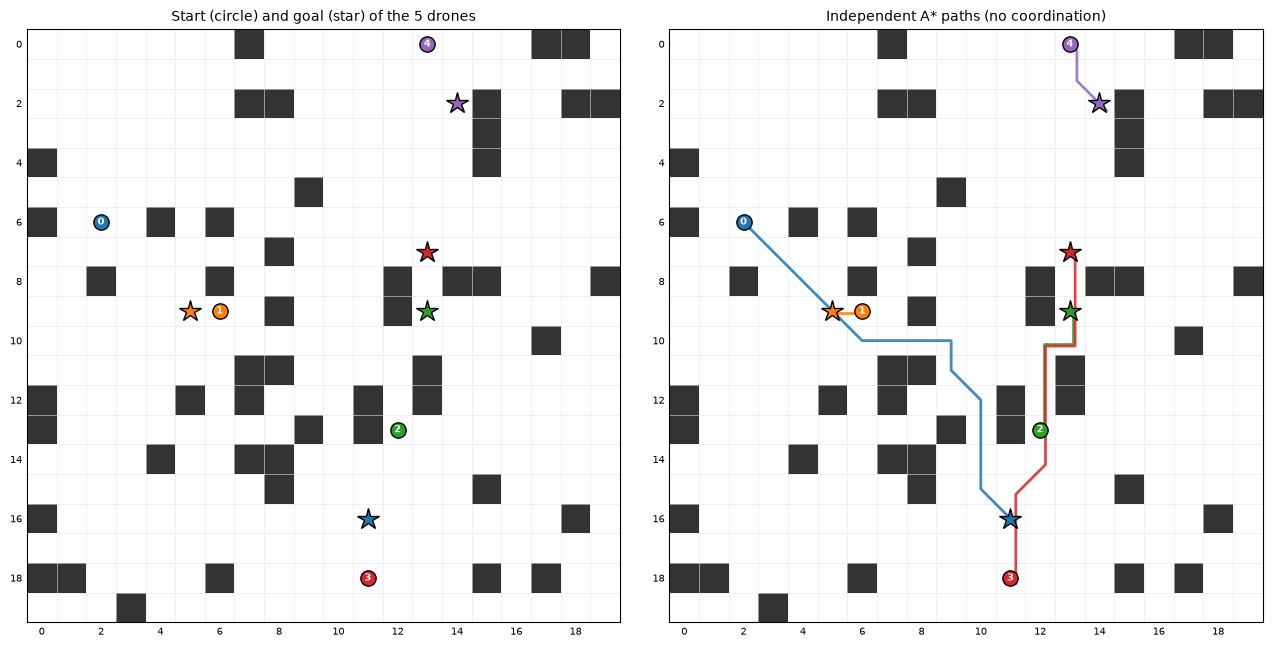

In [103]:
def draw_map(ax, title=""):
    # Draw the 20x20 map on the given plot area (ax)
    ax.imshow(env.grid, cmap=ListedColormap(["white", "#333333"]))                  #white= free cell, dark grey = obstacle
    ax.set_xticks(np.arange(-.5, env.w, 1), minor=True); ax.set_yticks(np.arange(-.5, env.h, 1), minor=True)   #small ticks between cells, used for the grid lines
    ax.grid(which="minor", color="#e6e6e6", lw=.4); ax.tick_params(which="both", length=0, labelsize=7)         #light grid lines, no tick marks, small labels
    ax.set_xticks(range(0, env.w, 2)); ax.set_yticks(range(0, env.h, 2))          #whole-number cell labels
    ax.set_title(title, fontsize=10)                                              #title above the plot

def draw_drones(ax, drones, paths=True):
    #Draw start, goal and (optionally) the path of every drone
    for d in drones:
        c = COLORS[d.id]                                        #every drone keeps its own colour in all plots
        if paths and d.path:                                                      #draw the path only if requested and it exists
            ax.plot([p[0] + .06 * d.id for p in d.path], [p[1] + .06 * d.id for p in d.path], "-", color=c, lw=2, alpha=.85)   # small shift per drone so overlapping paths stay visible
        ax.plot(*d.start, "o", color=c, ms=11, mec="k", zorder=5)                 # start = circle
        ax.text(*d.start, str(d.id), color="w", ha="center", va="center", fontsize=7, weight="bold", zorder=6)   # drone number written inside the circle
        ax.plot(*d.goal, "*", color=c, ms=16, mec="k", zorder=5)                  # goal = star

fig, ax = plt.subplots(1, 2, figsize=(13, 6.3))            #two plots side by side
draw_map(ax[0], "Start (circle) and goal (star) of the 5 drones"); draw_drones(ax[0], drones5, paths=False)   #left: only starts and goals
draw_map(ax[1], "Independent A* paths (no coordination)"); draw_drones(ax[1], drones5)                        #right: the paths of independent A*
plt.tight_layout(); plt.show()                             #arrange neatly and display

### 4.3 Scenario 1 (2 drones) and Scenario 2 (5 drones): independent A\* vs. prioritized planning

In [104]:
# runing both methods on both scenarios
METHODS = {"Independent A*": "plan_independent", "Prioritized planning": "plan_prioritized"}    #label shown in tables = name of the method in Coordinator
results = {}                                       #will store (drones, metrics) for every scenario and method
for n in (2, 5):                       #Scenario 1 = 2 drones, Scenario 2 = 5 drones
    for label, method in METHODS.items():               #run the baseline and then the coordinated method
        results[(f"Scenario {1 if n == 2 else 2} ({n} drones)", label)] = run_method(agents[n], method)    # key = (scenario name, method name)

#results tables
metrics = pd.DataFrame({k: v[1] for k, v in results.items()})          #numeric table (used by the plots)
display(pd.DataFrame({k: {m: f"{v:g}" for m, v in d.items()} for k, (_, d) in results.items()}))   #nicely formatted copy (:g removes useless decimals, e.g. 1.0 -> 1)

Scenario 1 (2 drones)                      Scenario 2 (5 drones)                     
                                Independent A* Prioritized planning        Independent A* Prioritized planning
Total travel distance                    16.49                16.49                 36.31                37.73
Conflicts (total)                            1                    0                     2                    0
   vertex                                    1                    0                     2                    0
   swap                                      0                    0                     0                    0
   crossing                                  0                    0                     0                    0
Agents reaching goal (%)                   100                  100                   100                  100
Completion time (steps)                     13                   13                    13                   13
Execution time (ms)                        0.6                 55.8                     1                   88

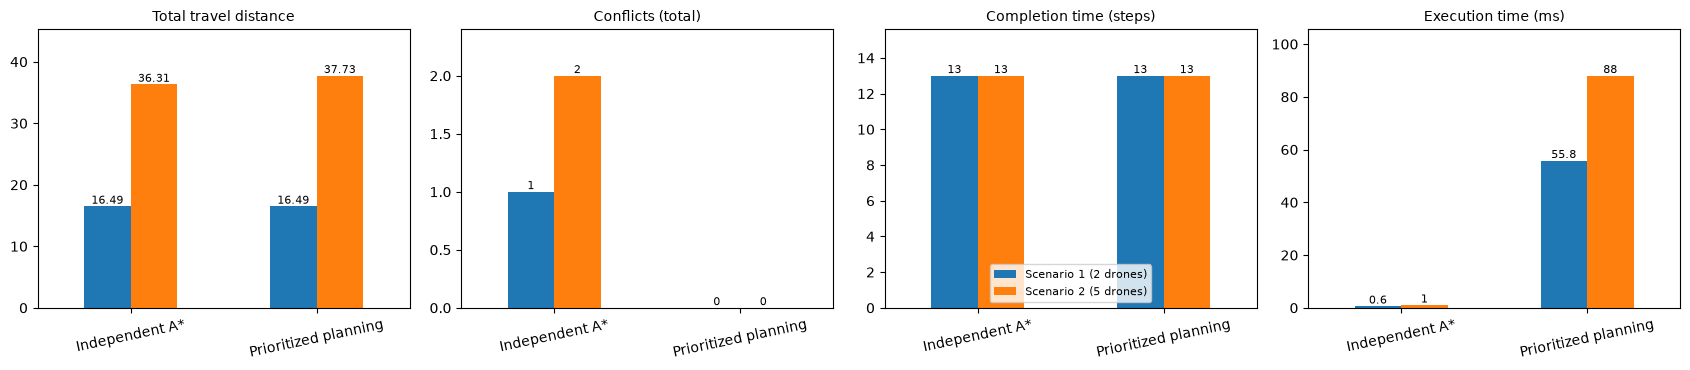

In [105]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))            #4 bar charts side by side, one per metric
for a, m in zip(ax, ["Total travel distance", "Conflicts (total)", "Completion time (steps)", "Execution time (ms)"]):   # pair each plot area with one metric
    metrics.loc[m].unstack(0).plot.bar(ax=a, rot=12, legend=(m == "Completion time (steps)"))     # bars: one group per method, one colour per scenario; legend only on one plot
    a.set_title(m, fontsize=10); a.set_xlabel(""); a.margins(y=0.2)       #title, no x-axis label, extra space above the bars so numbers fit
    if a.get_legend(): a.legend(fontsize=8, loc="lower center")                #small legend placed at the bottom centre (where it does not hide bars)
    for cont in a.containers:                                             #every group of bars...
        a.bar_label(cont, fmt="%.4g", fontsize=8)                   #...gets its value written on top
plt.tight_layout(); plt.show()                                            #arrange neatly and display

### 4.4 Visualisation of the coordinated movement

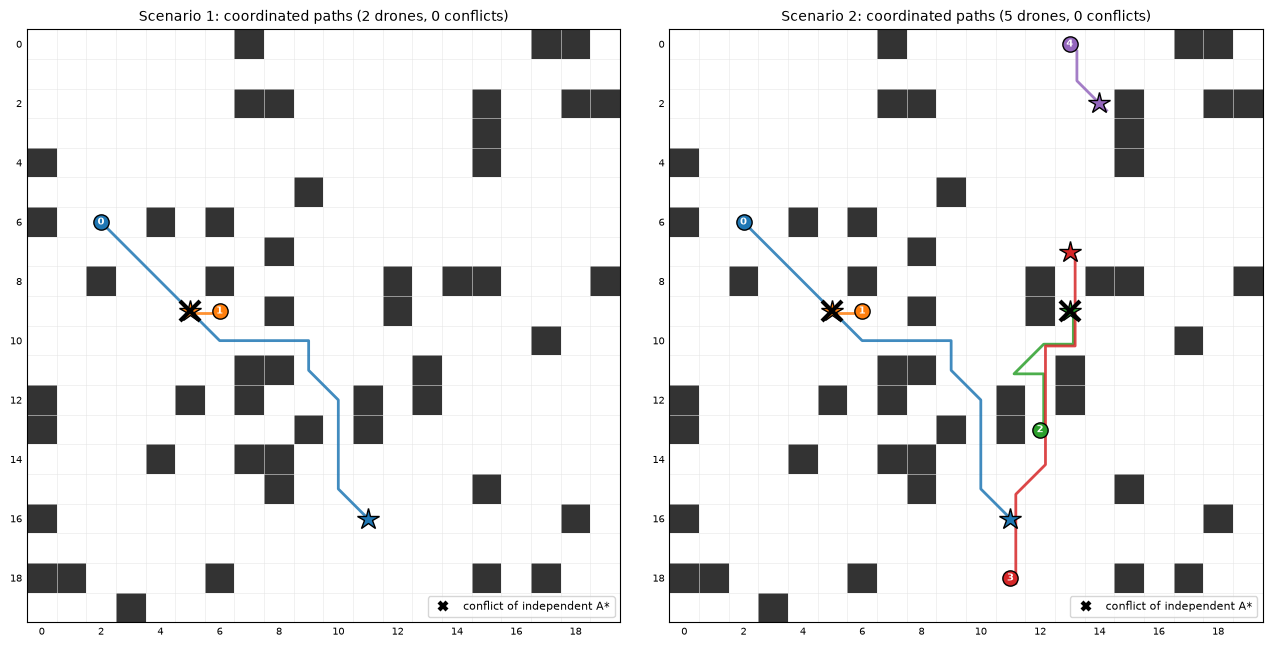

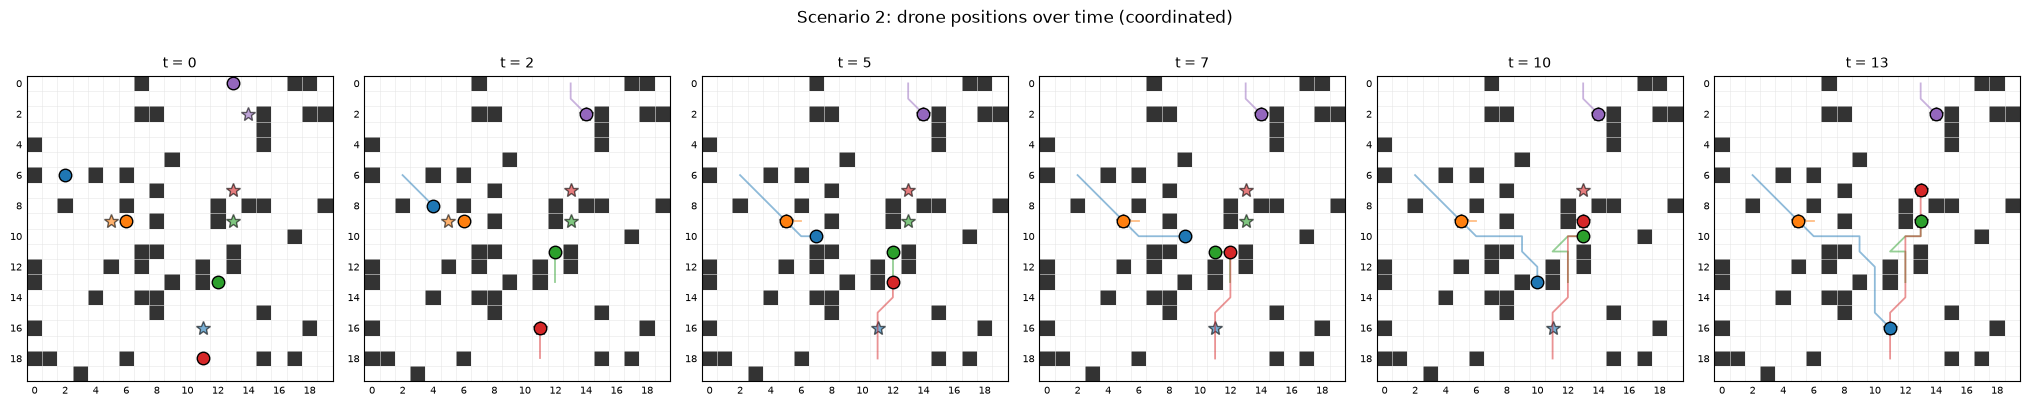

In [106]:
#Plot1: coordinated paths + the places where independent A* collides (black x)
fig, ax = plt.subplots(1, 2, figsize=(13, 6.3))       
for a, n in zip(ax, (2, 5)):
    key = (f"Scenario {1 if n == 2 else 2} ({n} drones)", "Prioritized planning")         # key to find the coordinated result in "results"
    draw_map(a, f"Scenario {1 if n == 2 else 2}: coordinated paths ({n} drones, "
                f"{results[key][1]['Conflicts (total)']} conflicts)")                       # title also shows the number of conflicts left (0)
    draw_drones(a, results[key][0])                        #draw start, goal and coordinated path of every drone
    base = results[(key[0], "Independent A*")][0]          #the drones planned WITHOUT coordination (baseline)
    for t in range(max(len(d.path) for d in base)):                   #mark where the baseline collides
        for i, j in itertools.combinations(range(len(base)), 2):      #every pair of drones
            if base[i].at(t) == base[j].at(t):                        #same cell at the same time = collision
                a.plot(*base[i].at(t), "kx", ms=14, mew=3, zorder=9)  #black x at that cell
    a.plot([], [], "kx", mew=3, label="conflict of independent A*"); a.legend(loc="lower right", fontsize=8)   #empty plot, only to create the legend entry
plt.tight_layout(); plt.show()                           

#Plot 2: snapshots of the 5-drone mission at different time steps 
drs = results[("Scenario 2 (5 drones)", "Prioritized planning")][0]      #the 5 coordinated drones
T = max(d.arrival_time for d in drs); times = sorted(set(np.linspace(0, T, 6).astype(int)))     #T= last arrival; pick 6 evenly spaced moments from 0 to T
fig, ax = plt.subplots(1, len(times), figsize=(3.4 * len(times), 3.9))   #one small map per chosen moment
for a, t in zip(ax, times):
    draw_map(a, f"t = {t}")                                #title= the time step
    for d in drs:
        trail = [d.at(k) for k in range(t + 1)]            #all positions of the drone from time 0 up to time t
        a.plot([p[0] for p in trail], [p[1] for p in trail], "-", color=COLORS[d.id], lw=1.3, alpha=.5)   
        a.plot(*d.goal, "*", color=COLORS[d.id], ms=10, mec="k", alpha=.6)                                  # star= goal
        a.plot(*d.at(t), "o", color=COLORS[d.id], ms=9, mec="k", zorder=5)                                  # circle = current position at time t
plt.suptitle("Scenario 2: drone positions over time (coordinated)", y=1.02); plt.tight_layout(); plt.show()  

In [107]:
def wait_steps(d):
                                                # Count how many time steps a drone waited (stayed in the same cell)
    return sum(1 for a, b in zip(d.path, d.path[1:]) if a == b)     # compare each cell with the next one;same cell= then waited

                                               #short before/after summary for each scenario
for n in (2, 5):                                          
    sc = f"Scenario {1 if n == 2 else 2} ({n} drones)"     # scenario name used as key in the tables
    ind, pri = metrics[(sc, "Independent A*")], metrics[(sc, "Prioritized planning")]     #metrics of the baseline (ind) and of the coordinated method (pri)
    waits = {d.id: wait_steps(d) for d in results[(sc, "Prioritized planning")][0] if wait_steps(d)}   #{drone number: waiting steps}, only drones that waited
    print(f"{sc}: conflicts {ind['Conflicts (total)']} -> {pri['Conflicts (total)']}, "             # conflicts: before -> after
          f"distance {ind['Total travel distance']} -> {pri['Total travel distance']}, "                     #distance: before -> after
          f"completion time {ind['Completion time (steps)']} -> {pri['Completion time (steps)']} steps, "        #mission time: before -> after
          f"waiting steps per drone: {waits if waits else 'none'}")                                        #which drones waited and for how lon

Scenario 1 (2 drones): conflicts 1.0 -> 0.0, distance 16.49 -> 16.49, completion time 13.0 -> 13.0 steps, waiting steps per drone: {1: 3}
Scenario 2 (5 drones): conflicts 2.0 -> 0.0, distance 36.31 -> 37.73, completion time 13.0 -> 13.0 steps, waiting steps per drone: {1: 3, 2: 5}


**Reading the results.** Independent A\* gives every drone its own shortest path, but two paths meet in the same cell at the same time step. The black × in the plot shows where the independent shortest paths meet. Prioritized planning removes these conflicts: the lower-priority drone **waits** (or takes a short detour) while the higher-priority drone passes. Because *waiting costs no distance*, the total travel distance stays the same (or grows only slightly if a detour is used) – the price of safety is paid in **time** (possible extra waiting steps) and in a slightly higher **planning time** (the search also has a time dimension). All drones reach their goals (100 %).

# 5. Test Cases


In [108]:

def small_grid(rows):
    # Building a small test map from text:@ = obstacle, . = free cell
    return Grid(np.array([[1 if ch == "@" else 0 for ch in r] for r in rows]))

def valid_path(g, path):
    # True if every step of the path is a legal move (wait, or a move to a neighbour cell)
    return all(a == b or any(n == b for n, _ in g.neighbors(a)) for a, b in zip(path, path[1:]))

#test1: A* on an empty grid 
def test_astar_empty_grid():                 # 4 diagonal moves from corner to corner
    g = small_grid(["....."] * 5); p = Planner(g).plan((0, 0), (4, 4))              # empty 5 x 5 grid, go from one corner to the opposite corner
    assert len(p) == 5 and abs(sum(Grid.step_cost(a, b) for a, b in zip(p, p[1:])) - 4 * SQRT2) < 1e-9   # 5 cells in the path and total cost = 4 diagonal steps

#test2: A* goes around obstacles, and returns None if the goal is cut off
def test_astar_avoids_obstacles_and_unreachable():
    g = small_grid(["..@..", "..@..", "..@..", ".....", "....."]); p = Planner(g).plan((0, 0), (4, 0))   # a wall blocks the direct way
    assert all(g.free(c) for c in p) and valid_path(g, p) and len(p) - 1 > 4        # path uses only free cells, legal moves, and is longer than the straight line
    assert Planner(small_grid([".@."])).plan((0, 0), (2, 0)) is None          # goal cut off by a wall

#test3: no corner cutting
def test_no_corner_cutting():
    g = small_grid([".@", "@."]); assert list(g.neighbors((0, 0))) == []      # diagonal squeeze is forbidden (both side cells are obstacles)
#test4: the drones of the experiment are valid
def test_scenario_entries_are_valid():      # all drones of the experiment start/end on free cells inside the window
    for r in agents5.itertuples():
        assert env.free((r.sx, r.sy)) and env.free((r.gx, r.gy)) and max(r.sx, r.sy, r.gx, r.gy) < N   # free cells and inside the 20 x 20 window

#test5: conflict counting 
def test_conflict_detection():
    assert find_conflicts({0: [(0, 0), (1, 0), (2, 0)], 1: [(2, 0), (1, 0), (0, 0)]})["vertex"] == 1        # meet in the middle
    assert find_conflicts({0: [(0, 0), (1, 0)], 1: [(1, 0), (0, 0)]})["swap"] == 1                           # swap cells
    assert find_conflicts({0: [(0, 0), (1, 1)], 1: [(1, 0), (0, 1)]})["crossing"] == 1                       # diagonal cross
    assert sum(find_conflicts({0: [(0, 0), (1, 0)], 1: [(0, 2), (1, 2)]}).values()) == 0                     # no conflict

#test6: two drones flying towards each other
def test_head_on_drones_are_coordinated():   # two drones fly towards each other in an open 7x3 area
    g = small_grid(["......."] * 3); d = [Drone(0, (0, 1), (6, 1)), Drone(1, (6, 1), (0, 1))]    # drone 0 goes left to right, drone 1 right to left
    Coordinator(g).plan_independent(d); assert sum(find_conflicts({x.id: x.path for x in d}).values()) > 0   # without coordination they collide
    Coordinator(g).plan_prioritized(d)                                                                       # now plan with coordination
    assert sum(find_conflicts({x.id: x.path for x in d}).values()) == 0 and all(x.reached for x in d)       # no collision and both reach their goals

# test7: narrow corridor with a side pocket
def test_waiting_in_a_corridor():            #1-wide corridor with a side pocket: one drone must step into the pocket
    g = small_grid(["@@.@@", ".....", "@@@@@"]); d = [Drone(0, (0, 1), (4, 1)), Drone(1, (3, 1), (1, 1))]
    Coordinator(g).plan_independent(d); assert find_conflicts({x.id: x.path for x in d})["swap"] > 0       #independent drones would swap cells
    Coordinator(g).plan_prioritized(d)
    assert sum(find_conflicts({x.id: x.path for x in d}).values()) == 0 and all(x.reached for x in d)       #coordinated: one drone steps into the pocket, no collision

# test 8: the real 5-drone experiment 
def test_coordinated_paths_are_valid():      #legal moves, correct start/goal, no collision, for the 5-drone experiment
    for d in results[("Scenario 2 (5 drones)", "Prioritized planning")][0]:
        assert d.path[0] == d.start and d.path[-1] == d.goal and valid_path(env, d.path)    #starts at the start, ends at the goal, all moves legal
    assert metrics[("Scenario 2 (5 drones)", "Prioritized planning")]["Conflicts (total)"] == 0     # no conflicts left

#  run all tests automatically 
tests = [v for k, v in sorted(globals().items()) if k.startswith("test_") and callable(v)]     #collecting here every function whose name starts with "test_"
for t in tests:
    try:
        t(); print("PASS ", t.__name__)                     #no error = the test passed
    except AssertionError as e:
        print("FAIL ", t.__name__, e)                      #a failed assert = then test failed

PASS  test_astar_avoids_obstacles_and_unreachable
PASS  test_astar_empty_grid
PASS  test_conflict_detection
PASS  test_coordinated_paths_are_valid
PASS  test_head_on_drones_are_coordinated
PASS  test_no_corner_cutting
PASS  test_scenario_entries_are_valid
PASS  test_waiting_in_a_corridor


# 6. Quantum Computing Extension

### 6.1 Which part of the problem could benefit from quantum optimisation?
Finding the path of *one* drone is easy (A\*). The hard part is the **joint decision**: *which combination of paths (and waiting times) of all drones is conflict-free and has the smallest total cost?* With `k` candidate paths per drone and `n` drones there are `kⁿ` combinations. This is a **combinatorial optimisation** problem, exactly the kind of problem that **quantum annealers** and algorithms such as **QAOA** try to solve, because they accept problems written as a QUBO.

### 6.2 QUBO representation
A QUBO asks for the binary vector `x` that minimises `E(x) = xᵀQx`. Here every binary variable selects one **candidate path** of one drone:

`x(i,p) = 1` if drone **i** uses candidate path **p**, else 0.

| Requirement | Penalty term in the energy |
|---|---|
| short, quick paths | `Σ cost(i,p) · x(i,p)` (cost = distance + 0.05 · arrival time) |
| each drone chooses **exactly one** path | `P · Σᵢ ( Σₚ x(i,p) − 1 )²` |
| no collision between two chosen paths | `W · c(i,p,j,q) · x(i,p) · x(j,q)`, where `c` = number of conflicts between the two paths |

A violated rule costs a large penalty (`P`, `W`), so the minimum-energy state is a valid, conflict-free plan with minimum cost. (A finer formulation uses `x(i, cell, time)` variables; it needs far more variables.)

### 6.3 Small quantum-inspired example
We apply this to the **5-drone instance above**. For every drone we build 9 candidate paths (up to 3 routes × waiting 0, 6 or 12 steps at the start) = **45 binary variables**. The QUBO is solved with **simulated annealing** (a classical, *quantum-inspired* method) and compared with the exact optimum (brute force over all 9⁵ = 59 049 combinations) and with prioritized planning.

In [109]:
planner = Planner(env)
TIME_W, P_ONE, W_CONF = 0.05, 100.0, 50.0     # time weight, one-path penalty (> any path cost), conflict penalty

def candidate_paths(d, delays=(0, 6, 12)):
    base = planner.plan(d.start, d.goal); routes = [base]
    for k in (len(base) // 3, 2 * len(base) // 3):                    # block one cell of the shortest path -> detour route
        if 0 < k < len(base) - 1:
            blocked = Grid(env.grid.copy()); blocked.grid[base[k][1], base[k][0]] = 1
            alt = Planner(blocked).plan(d.start, d.goal)
            if alt and alt not in routes:
                routes.append(alt)
    return [[d.start] * w + r for r in routes for w in delays]    # w waiting steps at the start

def path_cost(p):
    return sum(Grid.step_cost(a, b) for a, b in zip(p, p[1:])) + TIME_W * (len(p) - 1)

cands = {d.id: candidate_paths(d) for d in drones5}
var = [(i, k) for i in cands for k in range(len(cands[i]))]            # variable number -> (drone, candidate)
n_var = len(var)

# ---- build the QUBO matrix Q (upper triangular) ----
Q, offset = np.zeros((n_var, n_var)), 0.0
for a, (i, p) in enumerate(var):
    Q[a, a] += path_cost(cands[i][p]) - P_ONE                         # cost + linear part of the one-path penalty
    for b, (j, q) in enumerate(var):
        if b <= a:
            continue
        if i == j:
            Q[a, b] += 2 * P_ONE                                       # two paths of the same drone: penalty
        else:
            Q[a, b] += W_CONF * sum(find_conflicts({0: cands[i][p], 1: cands[j][q]}).values())
offset = P_ONE * len(cands)
print(f"{len(cands)} drones, {[len(v) for v in cands.values()]} candidate paths -> {n_var} binary variables, "
      f"{int(np.count_nonzero(Q))} non-zero QUBO coefficients")

5 drones, [9, 3, 9, 6, 6] candidate paths -> 33 binary variables, 201 non-zero QUBO coefficients


In [110]:
energy = lambda x: float(x @ Q @ x + offset)
                                   #energy of a solution x, lower energy means a better plan (cost + penalties)

def decode(x):
                                           # QUBO solution -> (plan, valid). valid = exactly one path per drone.
    pick = {i: [k for (ii, k), v in zip(var, x) if ii == i and v > .5] for i in cands}
                                             #for every drone, find which candidate paths are switched on (value 1)
    return {i: cands[i][ks[0]] for i, ks in pick.items() if len(ks) == 1}, all(len(ks) == 1 for ks in pick.values())
                                                  #gives the chosen path of each drone, and True only if every drone has exactly one path

def plan_summary(plan):
                                                            #small table of numbers for one complete plan
    return {"Total travel distance": round(sum(Grid.step_cost(a, b) for p in plan.values() for a, b in zip(p, p[1:])), 2),
                                                                       #distance of all drones together, waiting adds 0
            "Conflicts": sum(find_conflicts(plan).values()), "Completion time (steps)": max(len(p) - 1 for p in plan.values()),
                                                                 #number of collisions, and the time when the last drone arrives
            "QUBO objective": round(sum(path_cost(p) for p in plan.values()), 3)}
                                                                   #the number the QUBO wants to make small (distance plus small time penalty)

                                       # exact optimum: try all combinations of one candidate per drone
t0 = time.perf_counter(); best_e, best_x = math.inf, None
                                                    
for combo in itertools.product(*[range(len(cands[i])) for i in cands]):
                                             #every possible way to pick one candidate path for each drone
    x = np.zeros(n_var)
                                            #start with all bits 0
    for i, k in zip(cands, combo):
        x[var.index((i, k))] = 1
                                                 #switch on the bit of the chosen path of each drone
    e = energy(x)
                                             #energy of this combination
    if e < best_e:
        best_e, best_x = e, x
                                              #keep it if it is the best
exact_time = time.perf_counter() - t0
                                             

# simulated annealing: flip one bit at a time, accept worse states with probability exp(-delta/T)
def simulated_annealing(steps=80000, t0=30.0, t1=0.05, seed=0):
                                    #t0 = starting temperature (hot), t1 = final temperature (cold), seed makes the result repeatable
    rng = np.random.default_rng(seed); S = (Q + Q.T) / 2; np.fill_diagonal(S, np.diag(Q))
                                    #random number generator, and a symmetric copy of Q to make the calculation easy
    x = rng.integers(0, 2, n_var).astype(float); e = energy(x); bx, be = x.copy(), e
                                        #start from a random 0/1 solution, bx and be remember the best one seen
    for s in range(steps):
        T, k = t0 * (t1 / t0) ** (s / steps), rng.integers(n_var)
                                                                   #temperature goes down slowly, k is the random bit we try to flip
        delta = (1 - 2 * x[k]) * (2 * (S[k] @ x) - 2 * S[k, k] * x[k] + S[k, k])    # energy change of flipping bit k
        if delta <= 0 or rng.random() < math.exp(-delta / T):
                                                                  #always accept a better move, accept a worse move only sometimes (more often when hot)
            x[k] = 1 - x[k]; e += delta
                                                                       #flip the bit and update the energy
            if e < be - 1e-9:
                bx, be = x.copy(), e
                                                      #remembering the best solution
    return bx, be

t0 = time.perf_counter(); runs = [simulated_annealing(seed=s) for s in range(20)]; sa_time = (time.perf_counter() - t0) / 20
                                                               #run annealing 20 times with different seeds, sa_time is the average time of one run
sa_x, sa_e = min(runs, key=lambda r: r[1])

def good(x):                                               
    plan, valid = decode(x); return valid and sum(find_conflicts(plan).values()) == 0
hits = sum(abs(e - best_e) < 1e-6 for _, e in runs); feasible = sum(good(x) for x, _ in runs)
                                                             #hits = runs that found the exact best, feasible = runs that gave a valid plan with no conflicts
print(f"Exact minimum energy: {best_e:.3f} ({exact_time:.1f} s)  |  best SA energy: {sa_e:.3f}  (gap {100 * (sa_e - best_e) / best_e:.2f} %)")
                                                                    #exact best vs best annealing result, the gap shows how close annealing came
print(f"SA: {feasible}/20 runs gave a valid conflict-free plan, {hits}/20 hit the exact optimum, "
      f"mean energy {np.mean([e for _, e in runs]):.3f}  ({1000 * sa_time:.0f} ms per run)")
                                                                #summary of the 20 annealing runs

Exact minimum energy: 38.756 (0.1 s)  |  best SA energy: 39.056  (gap 0.77 %)
SA: 20/20 runs gave a valid conflict-free plan, 0/20 hit the exact optimum, mean energy 39.961  (667 ms per run)


,Total travel distance,Conflicts,Completion time (steps),QUBO objective
Independent A* (shortest paths),36.31,2.0,13.0,37.964
Prioritized planning (classical),37.73,0.0,13.0,39.828
QUBO exact optimum (brute force),36.56,0.0,13.0,38.756
QUBO + simulated annealing,36.56,0.0,13.0,39.056


SA solution valid (one path per drone): True


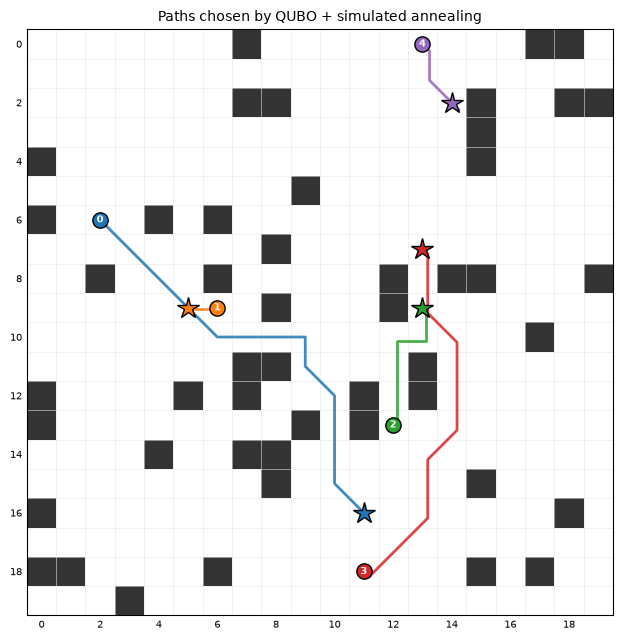

In [111]:
#compare the plans of all four methods on the same 5 drones
plans = {"Independent A* (shortest paths)": {d.id: d.path for d in results[("Scenario 2 (5 drones)", "Independent A*")][0]},          #method1: every drone alone (baseline)
         "Prioritized planning (classical)": {d.id: d.path for d in results[("Scenario 2 (5 drones)", "Prioritized planning")][0]},   #method2: coordinated, one drone after another
         "QUBO exact optimum (brute force)": decode(best_x)[0],      #method3: best possible choice among the candidate paths (found by trying all combinations)
         "QUBO + simulated annealing": decode(sa_x)[0]}              #method4: quantum-inspired search (simulated annealing) on the same QUBO
display(pd.DataFrame({k: plan_summary(v) for k, v in plans.items()}).T)      #table: one row per method (distance, conflicts, completion time, objective)
print("SA solution valid (one path per drone):", decode(sa_x)[1])    #True = simulated annealing chose exactly one path for every drone

#  draw the paths chosen by simulated annealing 
fig, ax = plt.subplots(figsize=(6.5, 6.5)); draw_map(ax, "Paths chosen by QUBO + simulated annealing")     # empty map
sa_drones = [Drone(i, d.start, d.goal) for i, d in enumerate(drones5)]       #new Drone objects with the same starts and goals
for d in sa_drones:
    d.path = decode(sa_x)[0][d.id]                                  #give each drone the path chosen by simulated annealing
draw_drones(ax, sa_drones); plt.tight_layout(); plt.show()                

### 6.4 Advantages and limitations of a quantum-assisted approach

**Advantages**
- It looks at **all drones together**. Prioritized planning plans one drone after another, so a bad order can give a worse result.
- Extra rules like no-fly zones, battery limits or preferred routes can be added easily as **extra penalty terms**.
- The same QUBO can be given to different solvers: simulated annealing (used here), a **quantum annealer** or **QAOA** on a gate-based quantum computer.

**Limitations**
- **Size:** the number of variables = drones × candidate paths. Even this tiny example has 33 variables, and a big map with many drones would need thousands. Today's quantum computers have only a few, noisy qubits.
- **Penalty weights** `P` and `W` must be chosen carefully. If they are too small, the answer can be invalid or still have collisions. If they are too large, the problem becomes hard to search.
- **Candidate paths** must be made first by a normal (classical) algorithm. The quantum part only chooses between them.
- **No guarantee:** simulated annealing is a heuristic, so it may not find the best answer. **We do not claim any quantum speed-up.** For this size, A\* + prioritized planning is faster and simpler. The quantum-inspired part is only a small proof of concept.

# 7. Discussion, Limitations and Possible Improvements

**Summary of results**
- A\* finds the shortest path for a drone around the obstacles. The test cases confirm this.
- When every drone plans alone (independent A\*), collisions happen in both Scenario 1 and Scenario 2.
- With **prioritized planning, all collisions are removed and every drone reaches its goal (100 %)**. The total distance stays the same or grows only a little (a small detour). The price is some waiting time and a longer planning time.
- The QUBO example shows that the same problem can be written as a binary optimisation problem. In the comparison table, the exact QUBO answer has a slightly shorter total distance than prioritized planning, because it chooses all the paths together.
- Simulated annealing finds valid plans without collisions, and they are close to the exact best answer. It does not always find the exact best, because it is a heuristic.

**Limitations**
- Prioritized planning is a **heuristic**, so it is not always the best answer. A bad priority order can even make a drone fail. We used "longest trip first", which is only one possible rule.
- The drones park at their goal and block that cell. The world is perfect: no wind, no delays, no drone size and no communication errors.
- We tested only 2 and 5 drones on one 20 × 20 map. The QUBO example is small and was not run on a real quantum computer.

**Possible improvements**
- Use better MAPF methods like **Conflict-Based Search (CBS)**, try several priority orders, or re-plan while the drones are flying.
- Test bigger maps with more drones, 3D movement and battery limits.
- Build bigger QUBOs with better penalty weights, and test them on a quantum annealer or a QAOA simulator.